# Food Platform Analysis: where does the growth come from, and who is about to leave?

This notebook analyses the cooking sessions of a recipe platform to help plan next year's strategy. It answers four questions:

1. **Which recipes work best**, in terms of volume and quality?
2. **Is the community growing?**
3. **Which groups of users exist**, and how do they behave?
4. **What drives the platform's success**, so that effort goes where it matters?

Each row of the data is one cooking session: which user cooked which recipe, when, on which device, and how many stars (1-5) they gave it. Every section ends with a plain-language takeaway, and the limitations of the analysis are listed at the end.

**Data dictionary**

| Column | Meaning |
|---|---|
| `cooking_date` | Date of the cooking session |
| `user_uuid` | User identifier |
| `category` | Recipe category (ethnic, breakfast, lunch, dinner, snack, smoothie, vegan) |
| `chef_id` | Identifier of the chef who created the recipe |
| `language`, `country` | Language and country of the user |
| `level` | Recipe difficulty (basic, intermediate, advanced) |
| `challenge_id` | Challenge the session belongs to; 0 is treated as "no challenge" |
| `subscription_date` | Date the user signed up |
| `platform` | Device used (mobile, pc, tv) |
| `recipe_id` | Recipe identifier |
| `stars` | Rating given by the user (1 to 5) |

## 1. Setup and data loading

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"  # avoids a known KMeans warning on some systems

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Global seed for every stochastic step (KMeans, PCA, bootstrap, simulations)
RANDOM_STATE = 2718

# Colour palette used throughout the notebook
GREEN, DARK, LIME, SAFFRON, GREY = "#2f6b43", "#16301f", "#b7e08a", "#f2a541", "#b8b3a0"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (12, 6), "font.size": 12})

In [2]:
# Works whether the notebook is run from the repository root or from the notebooks/ folder
DATA_PATH = next(p for p in [Path("data/Food_data_Final_Project.xlsx"),
                             Path("../data/Food_data_Final_Project.xlsx"),
                             Path("Food_data_Final_Project.xlsx"),
                             Path("Food_data Final Project.xlsx")] if p.exists())
df = pd.read_excel(DATA_PATH)
print(f"{df.shape[0]} sessions, {df.shape[1]} columns, {df['user_uuid'].nunique()} users")
print(f"Sessions from {df['cooking_date'].min().date()} to {df['cooking_date'].max().date()}")
print(f"Sign-ups from {df['subscription_date'].min().date()} to {df['subscription_date'].max().date()}")
df.head()

999 sessions, 12 columns, 242 users
Sessions from 2021-01-04 to 2023-12-28
Sign-ups from 2020-01-02 to 2022-12-23


,cooking_date,user_uuid,category,chef_id,language,level,challenge_id,country,subscription_date,platform,recipe_id,stars
0,2023-02-04,82,smoothie,109,fr,intermediate,1,fr,2022-01-21,pc,1251,1
1,2023-06-22,123,ethnic,122,fr,advanced,3,fr,2021-09-19,mobile,6347,1
2,2021-10-08,186,smoothie,105,fr,basic,0,fr,2020-08-12,tv,1152,5
3,2021-03-04,202,ethnic,118,fr,basic,3,fr,2020-02-04,tv,6140,2
4,2022-01-18,216,lunch,103,en,intermediate,1,uk,2021-10-08,pc,6248,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cooking_date       999 non-null    datetime64[us]
 1   user_uuid          999 non-null    int64         
 2   category           999 non-null    str           
 3   chef_id            999 non-null    int64         
 4   language           999 non-null    str           
 5   level              999 non-null    str           
 6   challenge_id       999 non-null    int64         
 7   country            999 non-null    str           
 8   subscription_date  999 non-null    datetime64[us]
 9   platform           999 non-null    str           
 10  recipe_id          999 non-null    int64         
 11  stars              999 non-null    int64         
dtypes: datetime64[us](2), int64(5), str(5)
memory usage: 93.8 KB


## 2. Data quality checks
We check missing values, duplicates, consistency between language and country, and time anomalies (a session dated before the user's sign-up).

In [4]:
print(f"Missing values: {int(df.isna().sum().sum())}")
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(f"Repeated user-recipe pairs: {df.duplicated(subset=['user_uuid', 'recipe_id']).sum()}")

print("\nSessions by (country, language):")
print(df.groupby(["country", "language"]).size())

anomalies = df[df["cooking_date"] < df["subscription_date"]]
print(f"\nSessions before the user's sign-up: {len(anomalies)}")

Missing values: 0
Exact duplicate rows: 0
Repeated user-recipe pairs: 1

Sessions by (country, language):
country  language
fr       fr          220
it       it          441
uk       en          338
dtype: int64

Sessions before the user's sign-up: 0


The data is clean: no missing values, no exact duplicates, language and country are consistent (one language per country), and no session happens before the user signed up. One user-recipe pair appears twice, which is plausible (a user cooking the same recipe again), so nothing is removed.

## 3. Feature engineering
Only the variables used later are created: calendar year and quarter of each session, and a flag for sessions that belong to a challenge.

In [5]:
df["cooking_year"] = df["cooking_date"].dt.year
df["cooking_quarter"] = df["cooking_date"].dt.to_period("Q").astype(str)
df["has_challenge"] = (df["challenge_id"] > 0).astype(int)
df[["cooking_date", "cooking_year", "cooking_quarter", "challenge_id", "has_challenge"]].head()

,cooking_date,cooking_year,cooking_quarter,challenge_id,has_challenge
0,2023-02-04,2023,2023Q1,1,1
1,2023-06-22,2023,2023Q2,3,1
2,2021-10-08,2021,2021Q4,0,0
3,2021-03-04,2021,2021Q1,3,1
4,2022-01-18,2022,2022Q1,1,1


## 4. First look at the data

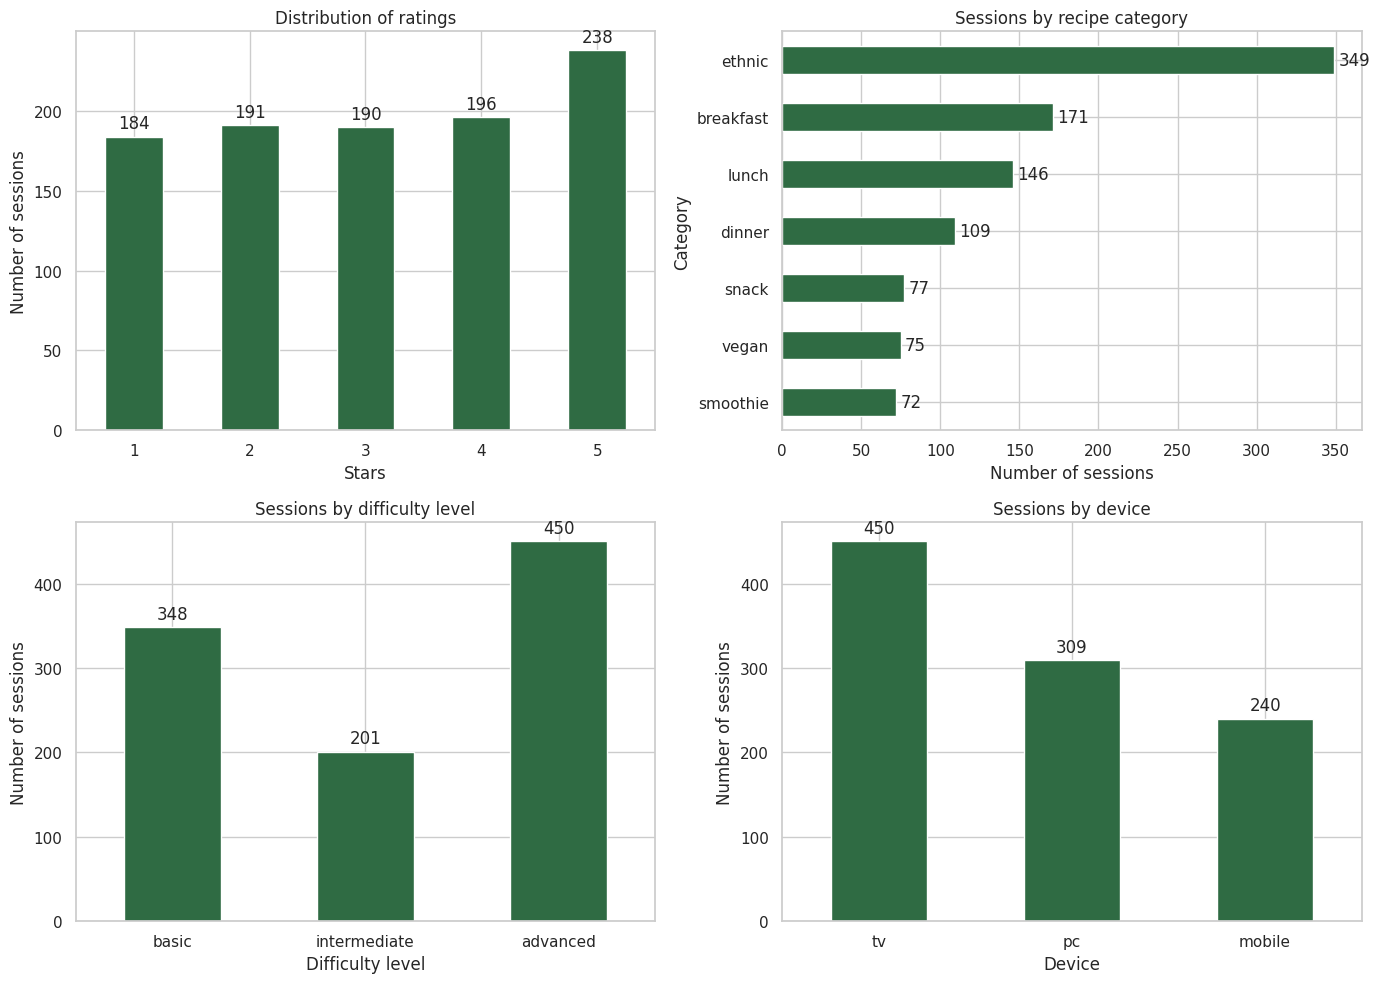

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df["stars"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 0], color=GREEN)
axes[0, 0].set_title("Distribution of ratings")
axes[0, 0].set_xlabel("Stars")
axes[0, 0].set_ylabel("Number of sessions")
axes[0, 0].tick_params(axis="x", rotation=0)

df["category"].value_counts().sort_values().plot(kind="barh", ax=axes[0, 1], color=GREEN)
axes[0, 1].set_title("Sessions by recipe category")
axes[0, 1].set_xlabel("Number of sessions")
axes[0, 1].set_ylabel("Category")

df["level"].value_counts().reindex(["basic", "intermediate", "advanced"]).plot(kind="bar", ax=axes[1, 0], color=GREEN)
axes[1, 0].set_title("Sessions by difficulty level")
axes[1, 0].set_xlabel("Difficulty level")
axes[1, 0].set_ylabel("Number of sessions")
axes[1, 0].tick_params(axis="x", rotation=0)

df["platform"].value_counts().plot(kind="bar", ax=axes[1, 1], color=GREEN)
axes[1, 1].set_title("Sessions by device")
axes[1, 1].set_xlabel("Device")
axes[1, 1].set_ylabel("Number of sessions")
axes[1, 1].tick_params(axis="x", rotation=0)

for ax in axes.flatten():
    for container in ax.containers:
        ax.bar_label(container, fmt="%d", padding=3)
plt.tight_layout()
plt.show()

**Takeaways**

- **Ratings** are spread fairly evenly across the five values (184, 191, 190, 196 and 238 sessions for 1 to 5 stars), with 5 stars the most frequent.
- **Ethnic recipes** are by far the most cooked (349 sessions, 35% of the total), followed by breakfast (171) and lunch (146).
- **Advanced** recipes are the most frequent level (450 sessions), then basic (348) and intermediate (201).
- **TV** is the most used device (450 sessions), then PC (309) and mobile (240).

## 5. Question 1: which recipes work best?
We define a recipe's **success** as a mix of two ingredients: **volume** (how many times it was cooked) and **quality** (its average rating). Both are rescaled between 0 and 1 and combined with equal weights.

We then look at the best recipes and at how quality varies by category and difficulty.

In [7]:
recipe_stats = df.groupby("recipe_id").agg(
    n_sessions=("user_uuid", "count"),
    avg_stars=("stars", "mean"),
    category=("category", "first"),
    level=("level", "first"),
).reset_index()

recipe_stats[["volume_scaled", "rating_scaled"]] = MinMaxScaler().fit_transform(recipe_stats[["n_sessions", "avg_stars"]])
recipe_stats["success_score"] = 0.5 * recipe_stats["volume_scaled"] + 0.5 * recipe_stats["rating_scaled"]

print(f"{len(recipe_stats)} recipes; sessions per recipe: median {recipe_stats['n_sessions'].median():.0f}, max {recipe_stats['n_sessions'].max()}")
recipe_stats.sort_values("success_score", ascending=False).head(10)[
    ["recipe_id", "category", "level", "n_sessions", "avg_stars", "success_score"]].round(2)

593 recipes; sessions per recipe: median 1, max 7


,recipe_id,category,level,n_sessions,avg_stars,success_score
562,6366,ethnic,advanced,7,3.71,0.84
407,6150,ethnic,basic,5,4.80,0.81
372,6110,lunch,basic,7,3.43,0.80
408,6151,lunch,basic,6,3.83,0.77
544,6347,ethnic,advanced,7,3.14,0.77
556,6359,ethnic,advanced,5,4.20,0.73
52,635,lunch,advanced,4,4.50,0.69
397,6137,ethnic,basic,5,3.80,0.68
549,6352,ethnic,advanced,5,3.60,0.66
530,6333,ethnic,advanced,4,4.25,0.66


Every recipe was cooked very few times (the most popular only 7), so a recipe's average rating rests on a handful of votes. The ranking above is therefore **indicative and unstable**, and it is more reliable to look at groups of recipes, as below.

In [8]:
cat_level = df.groupby(["category", "level"])["stars"].agg(["mean", "count"])
cat_level = cat_level[cat_level["count"] >= 5].sort_values("mean", ascending=False)
cat_level.round(2).head(10)

mean  count
category  level                    
vegan     intermediate  3.77     13
lunch     intermediate  3.56     36
smoothie  basic         3.52     25
snack     basic         3.44     27
smoothie  advanced      3.38     26
lunch     advanced      3.30     69
ethnic    intermediate  3.29     59
          advanced      3.22    152
vegan     advanced      3.18     40
breakfast basic         3.14     65

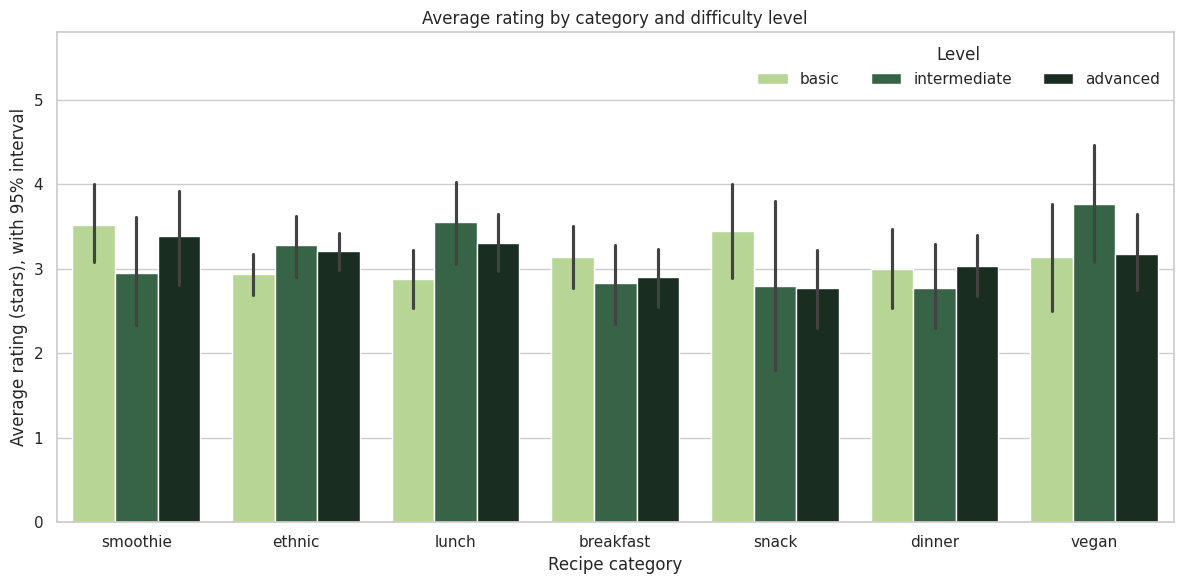

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df, x="category", y="stars", hue="level",
            hue_order=["basic", "intermediate", "advanced"],
            palette={"basic": LIME, "intermediate": GREEN, "advanced": DARK},
            errorbar=("ci", 95), seed=RANDOM_STATE, ax=ax)
ax.set_ylim(0, 5.8)
ax.set_xlabel("Recipe category")
ax.set_ylabel("Average rating (stars), with 95% interval")
ax.set_title("Average rating by category and difficulty level")
ax.legend(title="Level", frameon=False, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()

**Takeaways**

- **Ethnic recipes win on volume** (35% of sessions), but they are not the best rated (3.12 stars on average).
- **The highest-rated groups** with at least 5 sessions are vegan-intermediate (3.77 stars, 13 sessions), lunch-intermediate (3.56, 36 sessions), smoothie-basic (3.52, 25 sessions) and snack-basic (3.44, 27 sessions).
- **Intermediate recipes** get the best average rating (3.16) but are the least cooked (201 sessions, against 450 advanced and 348 basic).

**Handle with care.** The platform has 593 recipes, most cooked only once (the median is 1 session and the maximum 7), and the best-rated groups rest on 13 to 36 sessions. The intervals in the chart overlap heavily, and Section 8.1 shows that rating differences between categories and levels are not statistically distinguishable from chance. Shifting the catalogue towards intermediate recipes is therefore an idea to test, not a conclusion.

## 6. Question 2: is the community growing?
We look at sign-ups over time, and at activity (sessions and active users) by year and quarter.

In [10]:
new_users = df.drop_duplicates("user_uuid")[["user_uuid", "subscription_date"]].copy()
new_users["sub_year"] = new_users["subscription_date"].dt.year
signups = new_users.groupby("sub_year").size().rename("new users")
print("New users by sign-up year:")
print(signups)
print(f"\nAverage per month: {len(new_users) / 36:.1f} new users")

New users by sign-up year:
sub_year
2020    76
2021    91
2022    75
Name: new users, dtype: int64

Average per month: 6.7 new users


In [11]:
activity = df.groupby("cooking_year").agg(
    active_users=("user_uuid", "nunique"),
    sessions=("recipe_id", "count"),
    avg_stars=("stars", "mean"),
).round(3)
activity["sessions growth vs 2021 (%)"] = ((activity["sessions"] / activity["sessions"].iloc[0] - 1) * 100).round(0)
activity["active users growth vs 2021 (%)"] = ((activity["active_users"] / activity["active_users"].iloc[0] - 1) * 100).round(0)
activity

,active_users,sessions,avg_stars,sessions growth vs 2021 (%),active users growth vs 2021 (%)
cooking_year,,,,,
2021,62,108,3.000,0.0,0.0
2022,131,268,3.019,148.0,111.0
2023,216,623,3.173,477.0,248.0


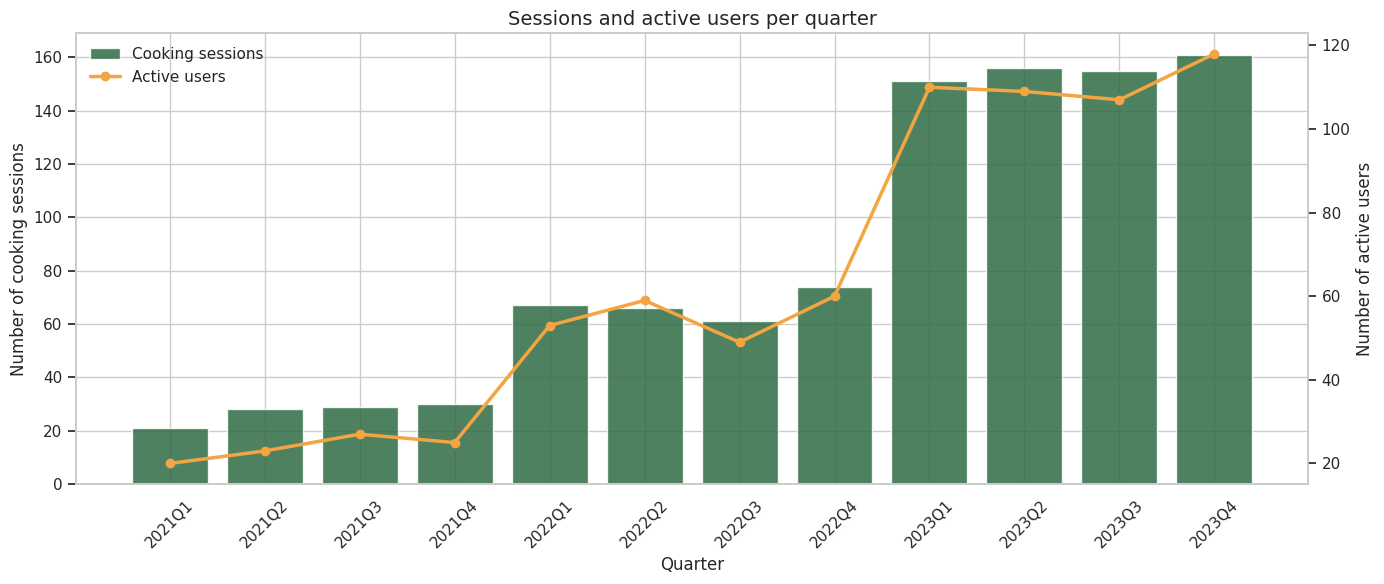

,cooking_quarter,sessions,active_users,sessions_per_active_user
0,2021Q1,21,20,1.05
1,2021Q2,28,23,1.22
2,2021Q3,29,27,1.07
3,2021Q4,30,25,1.20
4,2022Q1,67,53,1.26
5,2022Q2,66,59,1.12
6,2022Q3,61,49,1.24
7,2022Q4,74,60,1.23
8,2023Q1,151,110,1.37
9,2023Q2,156,109,1.43


In [12]:
quarterly = df.groupby("cooking_quarter").agg(
    sessions=("recipe_id", "count"),
    active_users=("user_uuid", "nunique"),
).reset_index()
quarterly["sessions_per_active_user"] = (quarterly["sessions"] / quarterly["active_users"]).round(2)

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.bar(quarterly["cooking_quarter"], quarterly["sessions"], color=GREEN, alpha=0.85, label="Cooking sessions")
ax1.set_xlabel("Quarter")
ax1.set_ylabel("Number of cooking sessions")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(quarterly["cooking_quarter"], quarterly["active_users"], marker="o", color=SAFFRON, linewidth=2.5, label="Active users")
ax2.set_ylabel("Number of active users")
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left")
plt.title("Sessions and active users per quarter", fontsize=14)
plt.tight_layout()
plt.show()

quarterly[["cooking_quarter", "sessions", "active_users", "sessions_per_active_user"]]

**Takeaways**

- **Sign-ups are flat:** 76 new users in 2020, 91 in 2021 and 75 in 2022, about 6.7 per month, with no growth trend.
- **Activity is growing fast and steadily.** Active users went from 62 (2021) to 216 (2023), a rise of 248%, and cooking sessions from 108 to 623, a rise of 477%.
- **Users are also cooking more each:** sessions per active user per quarter rose from about 1.05-1.2 in 2021 to about 1.4 in 2023.
- **Average rating** crept up from 3.00 to 3.17. This is a small change, and it was not tested for significance.

The community is not just expanding: the users it has are more engaged over time.

## 7. Question 3: which groups of users exist?
The raw data has one row per session, so we first need **one row per user**. For each of the 242 users we compute behaviour measures: how many recipes they cooked, how varied their choices are, how satisfied they are, how long ago they signed up and how recently they were active. We then try a standard clustering method. If it finds no real groups, we fall back on simple, interpretable behavioural segments.

### 7.1 Building the user profile

In [13]:
ref_date = df["cooking_date"].max()

user_features = df.groupby("user_uuid").agg(
    n_recipes=("recipe_id", "count"),
    n_categories=("category", "nunique"),
    n_chefs=("chef_id", "nunique"),
    avg_stars=("stars", "mean"),
    std_stars=("stars", "std"),
    last_cook=("cooking_date", "max"),
    first_cook=("cooking_date", "min"),
    subscription_date=("subscription_date", "first"),
    n_challenges=("challenge_id", lambda s: s[s > 0].nunique()),  # distinct challenges joined (0 means no challenge)
).reset_index()

user_features["recency_days"] = (ref_date - user_features["last_cook"]).dt.days
user_features["tenure_days"] = (ref_date - user_features["subscription_date"]).dt.days
user_features["activity_span_days"] = (user_features["last_cook"] - user_features["first_cook"]).dt.days
user_features["std_stars"] = user_features["std_stars"].fillna(0)

# Share of sessions by category, device and level (instead of one categorical value that changes over time)
cat_share = pd.crosstab(df["user_uuid"], df["category"], normalize="index").add_prefix("cat_").iloc[:, :-1]
platform_share = pd.crosstab(df["user_uuid"], df["platform"], normalize="index").add_prefix("platform_").iloc[:, :-1]
level_share = pd.crosstab(df["user_uuid"], df["level"], normalize="index").add_prefix("level_").iloc[:, :-1]

user_features = (user_features.merge(cat_share, on="user_uuid")
                              .merge(platform_share, on="user_uuid")
                              .merge(level_share, on="user_uuid"))

print(f"{len(user_features)} users, {user_features['n_recipes'].mean():.1f} sessions per user on average "
      f"(median {user_features['n_recipes'].median():.0f})")
user_features.describe().T[["mean", "min", "max"]].round(1).head(12)

242 users, 4.1 sessions per user on average (median 4)


,mean,min,max
user_uuid,123.384298,1.0,245.0
n_recipes,4.128099,1.0,11.0
n_categories,2.892562,1.0,6.0
n_chefs,3.793388,1.0,11.0
avg_stars,3.102956,1.0,5.0
std_stars,1.25623,0.0,2.828427
last_cook,2023-07-17 21:55:02.479338,2021-02-26 00:00:00,2023-12-28 00:00:00
first_cook,2022-06-17 12:11:54.049586,2021-01-04 00:00:00,2023-11-24 00:00:00
subscription_date,2021-06-22 22:12:53.553719,2020-01-02 00:00:00,2022-12-23 00:00:00
n_challenges,1.991736,0.0,3.0


The measures have very different scales (for example `n_recipes` goes from 1 to 11 while `tenure_days` goes from 370 to 1,456). To stop the largest-valued measures from dominating the distance between users, they are standardized.

In [14]:
core_cols = ["n_recipes", "n_categories", "n_chefs", "avg_stars", "std_stars",
             "recency_days", "tenure_days", "activity_span_days", "n_challenges"]
share_cols = list(cat_share.columns) + list(platform_share.columns) + list(level_share.columns)
feature_cols = core_cols + share_cols

X_scaled = StandardScaler().fit_transform(user_features[feature_cols].fillna(0).values)
print(f"{len(feature_cols)} measures per user ({len(core_cols)} behaviour measures + {len(share_cols)} category/device/level shares)")

19 measures per user (9 behaviour measures + 10 category/device/level shares)


### 7.2 Attempt 1: K-Means on all measures
K-Means is run for 2 to 10 clusters. The **elbow method** looks for a bend in the total within-cluster distance (inertia), and the **silhouette score** measures how well separated the clusters are, from -1 to 1. By the usual guideline (Kaufman and Rousseeuw), values below about 0.25 indicate no substantial structure.

In [15]:
ks = list(range(2, 11))
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

pd.DataFrame({"k": ks, "inertia": np.round(inertias, 1), "silhouette": np.round(silhouettes, 3)}).set_index("k").T

k,2,3,4,5,6,7,8,9,10
inertia,3941.100,3712.600,3519.90,3381.60,3215.200,3076.800,2990.600,2862.200,2775.700
silhouette,0.168,0.117,0.06,0.06,0.079,0.076,0.071,0.085,0.081


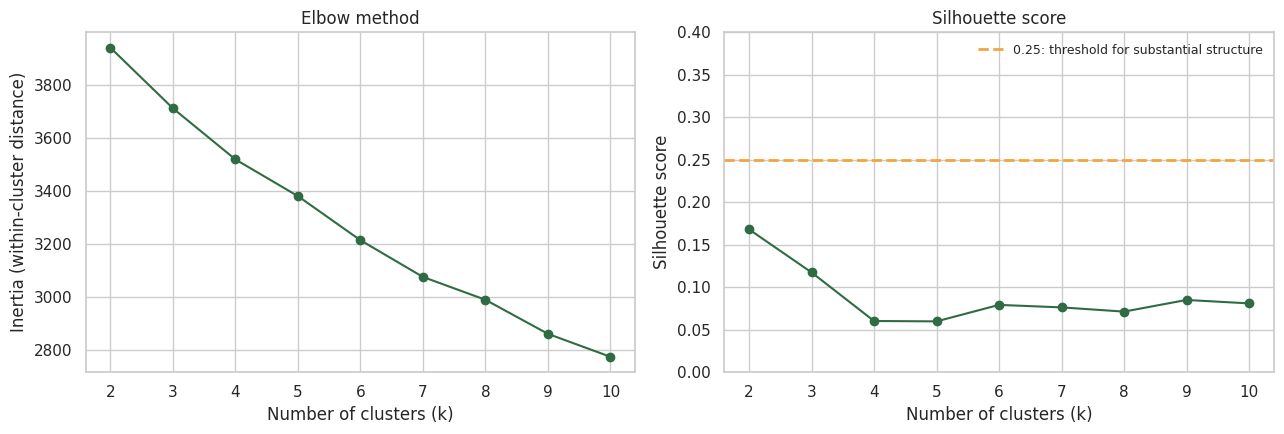

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inertias, marker="o", color=GREEN)
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster distance)")
axes[0].set_title("Elbow method")

axes[1].plot(ks, silhouettes, marker="o", color=GREEN)
axes[1].axhline(0.25, color=SAFFRON, linestyle="--", linewidth=2, label="0.25: threshold for substantial structure")
axes[1].set_ylim(0, 0.4)
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score")
axes[1].legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

**Result.** Inertia decreases steadily from 3,941 to 2,776 without a clear elbow, and the silhouette score is **below 0.17 for every k**, with its maximum at k=2 (0.168) and values around 0.06-0.12 afterwards. All are well under the 0.25 guideline for "substantial structure": K-Means finds no well-separated groups in this 19-dimensional space.

### 7.3 Visual check: is there hidden structure?
We reduce the nine behaviour measures to their two main components (PCA) and look at the users on a plane.

Share of variance explained: [44. 16.] %

What each component is made of (loadings):
                     PC1   PC2
n_recipes           0.47 -0.05
n_categories        0.42 -0.03
n_chefs             0.46 -0.03
avg_stars           0.03 -0.10
std_stars           0.26 -0.11
recency_days       -0.27  0.41
tenure_days         0.06  0.79
activity_span_days  0.34  0.43
n_challenges        0.36 -0.02


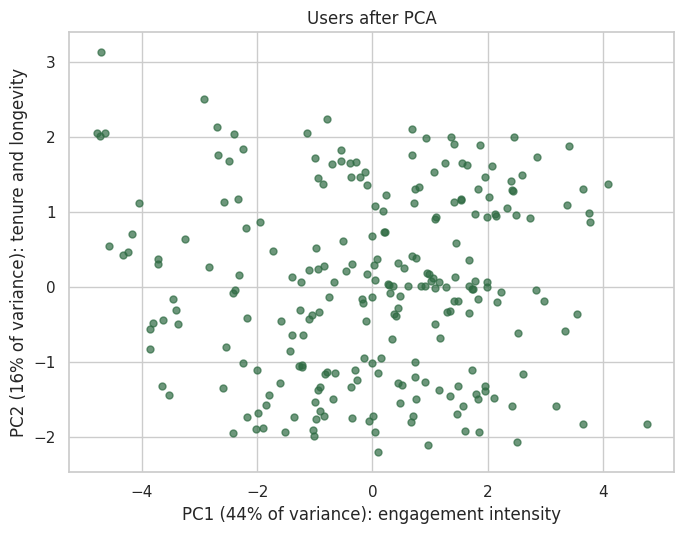

In [17]:
X_core = StandardScaler().fit_transform(user_features[core_cols].fillna(0))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_core)

loadings = pd.DataFrame(pca.components_.T, index=core_cols, columns=["PC1", "PC2"]).round(2)
print("Share of variance explained:", (pca.explained_variance_ratio_ * 100).round(0), "%")
print("\nWhat each component is made of (loadings):")
print(loadings)

plt.figure(figsize=(7, 5.5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=25, alpha=0.7, color=GREEN)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% of variance): engagement intensity")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% of variance): tenure and longevity")
plt.title("Users after PCA")
plt.tight_layout()
plt.show()

**Observation.** The scatter plot is a single continuous cloud of points, without arms or visibly separated groups. The loadings show what the two axes mean:

- **PC1 (44% of the variance)** is driven by `n_recipes`, `n_chefs`, `n_categories` and `n_challenges`: it is the **intensity of engagement**.
- **PC2 (16% of the variance)** is driven mainly by `tenure_days` (0.79), `activity_span_days` and `recency_days`: it is the **longevity** of the user on the platform.

Users vary continuously along these two axes rather than falling into distinct groups.

### 7.4 Attempt 2: K-Means after PCA, compared with data that has no groups
Running K-Means on the two components is a fair second attempt, but silhouette scores in 2 dimensions are naturally higher than in 20 dimensions, so the 0.25 guideline no longer applies. To judge the result we need a **reference**: the silhouette we would get on a structureless cloud with the same spread. We simulate 100 such clouds (a bivariate normal distribution with the same covariance as the real users) and compare.

In [18]:
def kmeans_silhouettes(Z, ks, n_init):
    return [silhouette_score(Z, KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=n_init).fit_predict(Z)) for k in ks]

observed = kmeans_silhouettes(X_pca, ks, n_init=10)

rng = np.random.RandomState(RANDOM_STATE)
cov = np.cov(X_pca.T)
null = np.array([kmeans_silhouettes(rng.multivariate_normal([0, 0], cov, size=len(X_pca)), ks, n_init=3)
                 for _ in range(100)])

pca_check = pd.DataFrame({
    "Observed silhouette": np.round(observed, 3),
    "Structureless cloud, mean": null.mean(axis=0).round(3),
    "Structureless cloud, 95th percentile": np.percentile(null, 95, axis=0).round(3),
}, index=pd.Index(ks, name="k"))
pca_check["Above reference?"] = pca_check["Observed silhouette"] > pca_check["Structureless cloud, 95th percentile"]
pca_check

,Observed silhouette,"Structureless cloud, mean","Structureless cloud, 95th percentile",Above reference?
k,,,,
2,0.414,0.396,0.426,False
3,0.356,0.334,0.356,False
4,0.352,0.347,0.373,False
5,0.385,0.343,0.366,True
6,0.374,0.341,0.365,True
7,0.371,0.340,0.364,True
8,0.371,0.339,0.362,True
9,0.397,0.342,0.362,True
10,0.389,0.342,0.365,True


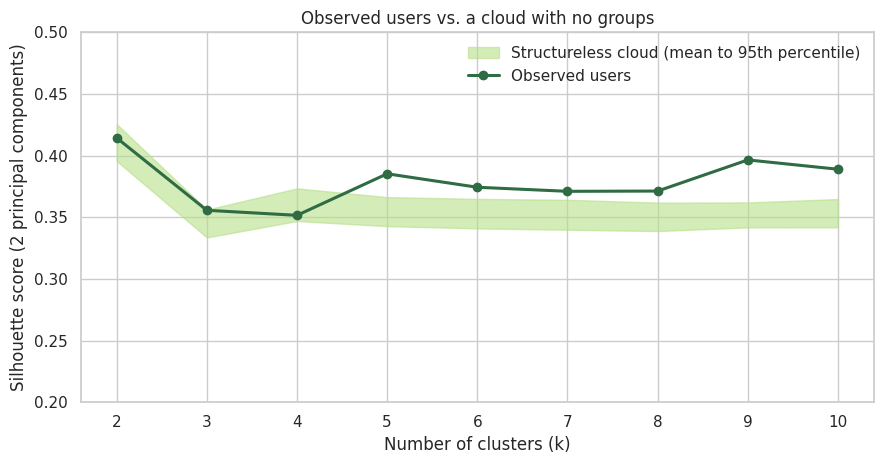

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.fill_between(ks, null.mean(axis=0), np.percentile(null, 95, axis=0), color=LIME, alpha=0.6,
                label="Structureless cloud (mean to 95th percentile)")
ax.plot(ks, observed, marker="o", color=GREEN, linewidth=2.2, label="Observed users")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score (2 principal components)")
ax.set_title("Observed users vs. a cloud with no groups")
ax.set_ylim(0.2, 0.5)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

**Result.** On the two components the observed silhouette scores (0.35-0.41) are high, but so are those of a cloud with no groups at all (0.34-0.40 on average). The real users exceed the 95th percentile of the structureless reference only for k=5 to 10, and by at most about 0.04; for k=2, 3 and 4, the practical choices, they do not exceed it. No value of k stands out, and the curve has no peak.

This confirms the first attempt: **users do not form distinct groups**. The small excess at larger k points to some unevenness in the cloud, not to clearly separated segments. We therefore keep the rule-based segmentation below.

### 7.5 Solution: behavioural segments based on rules (RFM-style)
Since there are no natural clusters, we build four segments that are easy to interpret by crossing two measures that match the two main components found above:

- **Frequency:** number of recipes cooked (`n_recipes`), how active the user is.
- **Recency:** days since the last session (`recency_days`), how recently the user was active.

The **median** of each measure is used as the cut-off, which produces balanced groups.

In [20]:
freq_median = user_features["n_recipes"].median()
rec_median = user_features["recency_days"].median()
print(f"Cut-offs: {freq_median:.0f} or more recipes = high frequency; {rec_median:.0f} days or fewer since last session = recent")

def segment(row):
    high_freq = row["n_recipes"] >= freq_median
    recent = row["recency_days"] <= rec_median
    if high_freq and recent:
        return "Active power user"
    if high_freq and not recent:
        return "At risk of churn"
    if not high_freq and recent:
        return "Occasional"
    return "Dormant"

user_features["segment"] = user_features.apply(segment, axis=1)
SEGMENT_ORDER = ["Active power user", "At risk of churn", "Occasional", "Dormant"]
seg_counts = user_features["segment"].value_counts().reindex(SEGMENT_ORDER)
seg_counts.to_frame("users").assign(share=lambda d: (d["users"] / d["users"].sum() * 100).round(0).astype(int).astype(str) + "%")

Cut-offs: 4 or more recipes = high frequency; 94 days or fewer since last session = recent


,users,share
segment,,
Active power user,84,35%
At risk of churn,56,23%
Occasional,41,17%
Dormant,61,25%


In [21]:
profile_cols = ["n_recipes", "n_categories", "n_chefs", "avg_stars", "recency_days", "tenure_days", "activity_span_days", "n_challenges"]
user_features.groupby("segment")[profile_cols].mean().round(1).reindex(SEGMENT_ORDER)

,n_recipes,n_categories,n_chefs,avg_stars,recency_days,tenure_days,activity_span_days,n_challenges
segment,,,,,,,,
Active power user,5.7,3.6,5.2,3.1,40.7,879.6,520.6,2.5
At risk of churn,5.2,3.5,4.7,3.3,198.6,1021.3,508.4,2.4
Occasional,2.5,2.0,2.4,3.2,46.3,793.8,301.8,1.6
Dormant,2.1,1.9,2.0,2.9,377.5,959.9,182.1,1.2


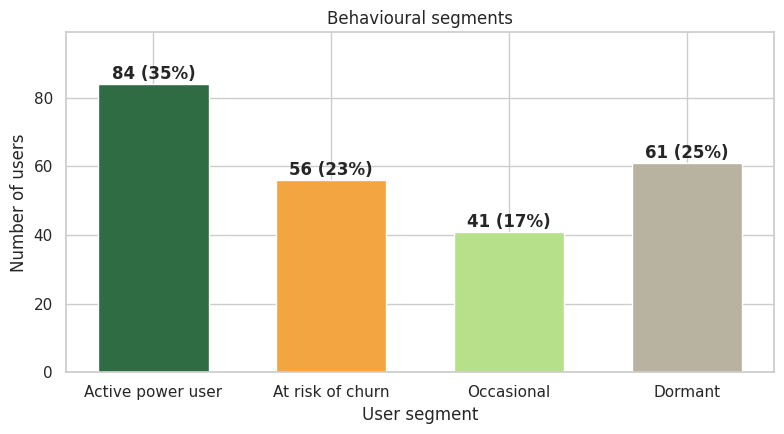

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(SEGMENT_ORDER, seg_counts.values, color=[GREEN, SAFFRON, LIME, GREY], width=0.62)
for i, v in enumerate(seg_counts.values):
    ax.text(i, v + 1.5, f"{v} ({v / len(user_features) * 100:.0f}%)", ha="center", fontweight="bold")
ax.set_ylim(0, seg_counts.max() * 1.18)
ax.set_xlabel("User segment")
ax.set_ylabel("Number of users")
ax.set_title("Behavioural segments")
plt.tight_layout()
plt.show()

**Interpretation of the segments**

- **Active power users (84 users, 35%)** cook a lot (5.7 recipes on average), explore several categories (3.6) and chefs (5.2), and were active about 41 days ago. They are the healthy core of the community.
- **At risk of churn (56 users, 23%)** were historically as active as the power users (5.2 recipes, 3.5 categories) and have the longest tenure (about 1,020 days), but have been absent for about 199 days. They are the **priority target for re-engagement campaigns**.
- **Occasional (41 users, 17%)** cook little (2.5 recipes) but did so recently (about 46 days ago). They have been subscribed for about 794 days on average, shorter than the other segments but more than two years, so "occasional" describes their activity, not a recent arrival.
- **Dormant (61 users, 25%)** cooked little (2.1 recipes) and have been inactive for about a year (378 days). They also have the lowest average rating (2.9), which may hint at dissatisfaction, although this difference was not tested and the groups are small. They are probably lost.

**Conclusion of the section.** Standard clustering finds no natural groups: user behaviour varies continuously along two dimensions, intensity of use and longevity or recency. The rule-based segmentation produces four balanced, interpretable groups, each with a clear business implication. The median cut-offs (4 recipes, 94 days) are a practical choice, not a natural boundary.

## 8. Question 4: what drives the platform's success?
The dataset has **no business metric** such as revenue, conversion or satisfaction surveys, so success has to be measured through proxies:

- **Growth:** new users acquired over time (`subscription_date`)
- **Engagement:** volume and frequency of use (sessions)
- **Satisfaction:** average rating (`stars`)
- **Retention:** share of users still active versus dormant (the segments above)

We test each available factor (category, chef, device, level, challenge, country, sign-up cohort) against these proxies, to see what really explains them.

### 8.1 Is satisfaction explained by category, device, level, chef or country?

In [23]:
for col in ["category", "platform", "level", "country"]:
    print(df.groupby(col)["stars"].agg(["mean", "count"]).round(2), "\n")

chef_stats = df.groupby("chef_id")["stars"].agg(["mean", "count"])
print(f"Chefs: {len(chef_stats)}, average rating from {chef_stats['mean'].min():.2f} to {chef_stats['mean'].max():.2f}, "
      f"with {chef_stats['count'].min()} to {chef_stats['count'].max()} sessions each")
print(f"\nAverage rating with a challenge: {df.loc[df['has_challenge'] == 1, 'stars'].mean():.2f} | without: {df.loc[df['has_challenge'] == 0, 'stars'].mean():.2f}")

           mean  count
category              
breakfast  2.98    171
dinner     2.96    109
ethnic     3.12    349
lunch      3.25    146
smoothie   3.31     72
snack      3.01     77
vegan      3.27     75 

          mean  count
platform             
mobile    3.14    240
pc        3.10    309
tv        3.11    450 

              mean  count
level                    
advanced      3.13    450
basic         3.07    348
intermediate  3.16    201 

         mean  count
country             
fr       3.07    220
it       3.12    441
uk       3.13    338 

Chefs: 23, average rating from 2.83 to 3.56, with 33 to 59 sessions each

Average rating with a challenge: 3.10 | without: 3.14


Differences between averages can come from chance, especially with few sessions per group, so they are tested formally. Ratings are ordinal (1 to 5), so we use the **Kruskal-Wallis test**, which compares groups without assuming a normal distribution. It gives a p-value (the probability of seeing differences at least this large if the factor made no real difference) and an effect size.
where $H$ is the test statistic, $k$ the number of groups and $n$ the number of sessions. It is close to 0 when the factor explains almost none of the differences in ratings. For the two-group comparison (challenge or not) we use the Mann-Whitney test.

In [24]:
n = len(df)
rows = []
for col in ["category", "platform", "level", "chef_id", "country"]:
    groups = [g["stars"].values for _, g in df.groupby(col)]
    H, p = stats.kruskal(*groups)
    k = len(groups)
    rows.append({"Factor": col, "Groups": k, "Test": "Kruskal-Wallis", "p-value": p, "Effect size": max((H - k + 1) / (n - k), 0)})

with_ch = df.loc[df["has_challenge"] == 1, "stars"]
without_ch = df.loc[df["has_challenge"] == 0, "stars"]
U, p = stats.mannwhitneyu(with_ch, without_ch)
rows.append({"Factor": "challenge (yes/no)", "Groups": 2, "Test": "Mann-Whitney",
             "p-value": p, "Effect size": abs(1 - 2 * U / (len(with_ch) * len(without_ch)))})

tests = pd.DataFrame(rows).set_index("Factor")
tests["p-value"] = tests["p-value"].round(3)
tests["Effect size"] = tests["Effect size"].round(3)
tests["Significant at 5%?"] = np.where(tests["p-value"] < 0.05, "yes", "no")
tests

,Groups,Test,p-value,Effect size,Significant at 5%?
Factor,,,,,
category,7,Kruskal-Wallis,0.364,0.001,no
platform,3,Kruskal-Wallis,0.947,0.000,no
level,3,Kruskal-Wallis,0.724,0.000,no
chef_id,23,Kruskal-Wallis,0.915,0.000,no
country,3,Kruskal-Wallis,0.895,0.000,no
challenge (yes/no),2,Mann-Whitney,0.719,0.015,no


In [25]:
challenge_stats = df.groupby("user_uuid").agg(n_recipes=("recipe_id", "count"), challenge_rate=("has_challenge", "mean"))
r = challenge_stats["n_recipes"].corr(challenge_stats["challenge_rate"])
print(f"Correlation between sessions per user and share of challenge sessions: {r:.3f}")

Correlation between sessions per user and share of challenge sessions: 0.029


**Result.** None of the factors explains satisfaction, and **no difference is statistically significant**: p-values range from 0.36 (category) to 0.95 (device), and all effect sizes are practically zero. The widest range of averages is across chefs (2.83 to 3.56 stars), but with only 33 to 59 sessions per chef that spread is entirely consistent with chance (p = 0.92). Challenge participation is also unrelated to how much a user cooks (correlation 0.03).

With this data we cannot say that any content factor (category, chef, difficulty) or the device makes users happier. Two cautions apply: not finding a difference is not proof that none exists, since with about 1,000 sessions only fairly large effects could be detected; and the factors were tested against satisfaction only (plus challenge against activity), so testing them against engagement and retention is a natural next step.

### 8.2 Does growth come from new users or from existing users being more active?

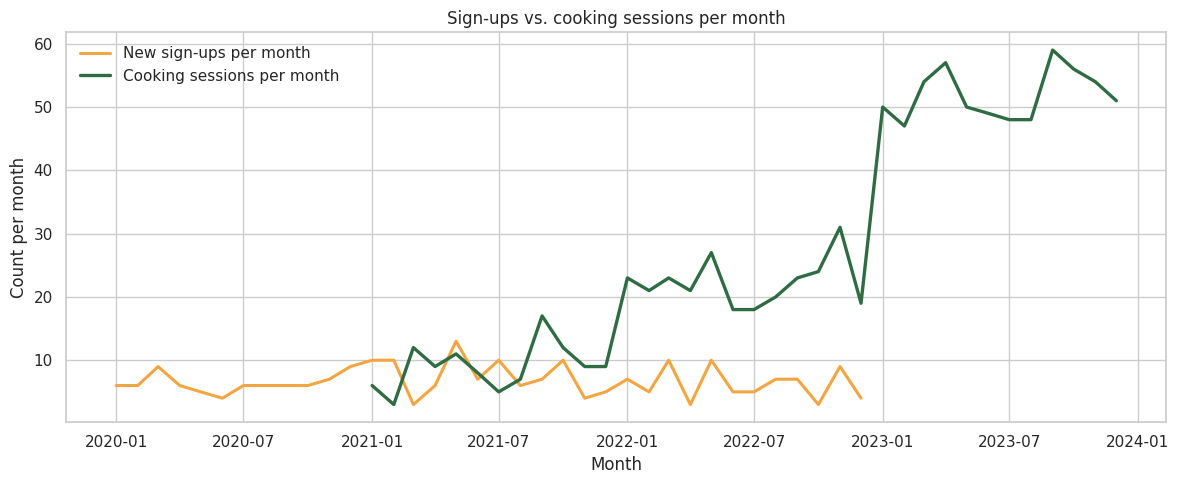

,sign-ups per month,sessions per month
2020,6.3,NaN
2021,7.6,9.0
2022,6.2,22.3
2023,NaN,51.9


In [26]:
users_unique = df.drop_duplicates("user_uuid")
events_month = df.groupby(df["cooking_date"].dt.to_period("M")).size().rename("sessions")
signups_month = users_unique.groupby(users_unique["subscription_date"].dt.to_period("M")).size().rename("sign-ups")
monthly = pd.concat([events_month, signups_month], axis=1).sort_index()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly["sign-ups"], color=SAFFRON, linewidth=2.2, label="New sign-ups per month")
ax.plot(monthly.index, monthly["sessions"], color=GREEN, linewidth=2.4, label="Cooking sessions per month")
ax.set_xlabel("Month")
ax.set_ylabel("Count per month")
ax.set_title("Sign-ups vs. cooking sessions per month")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

by_year = pd.DataFrame({
    "sign-ups per month": (users_unique.groupby(users_unique["subscription_date"].dt.year).size() / 12).round(1),
    "sessions per month": (df.groupby("cooking_year").size() / 12).round(1),
})
by_year

**Result.** Sign-ups have stayed at about 6-8 a month (6.3, 7.6 and 6.2 per month in 2020, 2021 and 2022), while cooking sessions per month rose from 9.0 in 2021 to 22.3 in 2022 and 51.9 in 2023, almost six times.

**The growth of the platform does not come from acquiring more users, which is stagnant, but from the engagement of existing users.** One caveat: users appear in the data only if they cooked at least once, so "sign-ups" here means users who signed up and cooked at least once.

### 8.3 Is engagement the same for every sign-up cohort, or improving over time?
We split activity by **sign-up cohort** (the year users signed up) and look at how much each cohort produces in its **first observed year** on the platform, which is a fairer comparison between cohorts.

In [27]:
users = users_unique[["user_uuid", "subscription_date"]].copy()
users["sub_year"] = users["subscription_date"].dt.year
df2 = df.merge(users[["user_uuid", "sub_year"]], on="user_uuid")
cohort_table = pd.crosstab(df2["cooking_year"], df2["sub_year"])
cohort_table.index.name = "session year"
cohort_table.columns.name = "sign-up cohort"
cohort_table

sign-up cohort,2020,2021,2022
session year,,,
2021,108,0,0
2022,101,167,0
2023,120,189,314


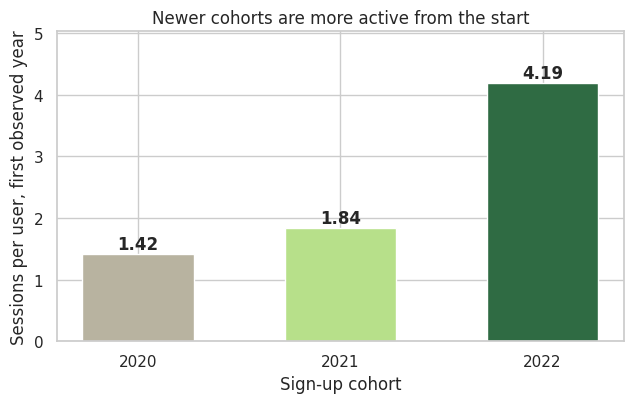

,users in cohort,sessions in first observed year,sessions per user,change vs previous cohort (%)
sign-up cohort,,,,
2020,76,108,1.42,NaN
2021,91,167,1.84,30.0
2022,75,314,4.19,128.0


In [28]:
cohort_size = users.groupby("sub_year").size()

# The first sessions of every cohort fall in the calendar year after sign-up (see the table above)
first_year_events = {cohort: int(cohort_table.loc[cohort + 1, cohort]) for cohort in cohort_size.index}
first_year = pd.DataFrame({
    "users in cohort": cohort_size,
    "sessions in first observed year": pd.Series(first_year_events),
})
first_year["sessions per user"] = (first_year["sessions in first observed year"] / first_year["users in cohort"]).round(2)
first_year["change vs previous cohort (%)"] = (first_year["sessions per user"].pct_change() * 100).round(0)
first_year.index.name = "sign-up cohort"

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.bar(first_year.index.astype(str), first_year["sessions per user"], color=[GREY, LIME, GREEN], width=0.55)
for i, v in enumerate(first_year["sessions per user"]):
    ax.text(i, v + 0.08, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, first_year["sessions per user"].max() * 1.2)
ax.set_xlabel("Sign-up cohort")
ax.set_ylabel("Sessions per user, first observed year")
ax.set_title("Newer cohorts are more active from the start")
plt.tight_layout()
plt.show()
first_year

**Result.** In their first observed year, cohorts produce 1.42, 1.84 and 4.19 sessions per user (the 2020, 2021 and 2022 cohorts): increases of 30% and then 128%, so the growth is not a constant progression.

Two things can be read from the cohort table:

- **Within a cohort, activity changes little over time:** the 2020 cohort cooks 108, 101 and 120 sessions in 2021, 2022 and 2023, and the 2021 cohort 167 and then 189. Older cohorts increased by 13-19% in 2023.
- **Each newer cohort starts at a clearly higher level**, surpassing the earlier cohorts' peaks. Most of the growth therefore comes from newer cohorts being more active from the start, not from older users cooking much more.

**Two cautions.** The jump of the 2022 cohort partly coincides with the general increase of activity in 2023, so it cannot be fully isolated as a pure cohort effect. And no cohort has any activity in its own sign-up year (the first session always falls in the following year), a pattern that may reflect how the data was generated rather than real behaviour.

## 9. Implications for next year

1. **Win back the "at risk of churn" segment first.** 56 users (23%) were as active as the best users and have been silent for about 200 days. They are a better bet than dormant users, who left almost a year ago.
2. **Understand and replicate what improved onboarding.** Newer cohorts become active much faster than older ones. Finding out why requires data that this dataset does not contain (product logs, feature usage, surveys), and the result should be applied to next year's new users.
3. **Look at acquisition and onboarding before reshaping the catalogue.** Content (category, chef, difficulty) and device show no significant link with ratings, while sign-ups have been flat. This is a **hypothesis to test**, for example with a small acquisition pilot: the dataset cannot show that more acquisition would produce more growth.
4. **Collect the missing data.** Acquisition channel, marketing spend, reasons for leaving and revenue would turn these descriptive findings into decisions with a measurable return.

## 10. Conclusions

**1. Which recipes work best?** Ethnic recipes are cooked the most (35% of sessions). Ratings are similar everywhere (2.96 to 3.31 stars by category), and the best-rated combinations rest on small samples, so no category or level can be called a clear winner.

**2. Is the community growing?** In activity, yes: sessions rose from 108 to 623 a year and active users from 62 to 216 between 2021 and 2023. New sign-ups did not grow (about 6-7 a month).

**3. Which groups of users exist?** No natural groups: users vary continuously in how much and how recently they use the platform. Four behavioural segments were built instead, and **23% of users are at risk of churn**.

**4. What drives success?** Not the content: category, chef, difficulty, device and country show no significant link with ratings. Growth comes from existing users being more active, and newer sign-up cohorts become active much faster than older ones.

**What I would do:** win back the at-risk users, work out what improved onboarding for the newer cohorts, and collect the data that would make the findings causal.